# 02 · Pune road network, wards, facilities, cameras and scenarios

Built from `data/processed` (run `make data` first). **Synthetic** elements: hospital capabilities,
incident generator, rain profile, procession timings. Speeds and multipliers are `UNVERIFIED`
(see `configs/geo.yaml`).

Map data © OpenStreetMap contributors (ODbL). Wards: PMC 2022 electoral wards, DataMeet (CC BY-SA 2.5 IN).

In [1]:
import json
import time
from datetime import timedelta

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

from resqcity.common.config import PROJECT_ROOT, find_unverified, load_base_config
from resqcity.common.requirements import load_requirements_config
from resqcity.geo.cameras import load_cameras
from resqcity.geo.config import load_geo_config
from resqcity.geo.facilities import load_facilities
from resqcity.geo.network import RoadNetwork
from resqcity.geo.scenario import ScenarioState, load_scenario
from resqcity.sim.generator import IncidentGenerator, load_incidents_config, to_frame

base, geo = load_base_config(), load_geo_config()
processed = base.paths.resolve("data_processed")
t0 = time.perf_counter()
net = RoadNetwork.load(processed, geo)
print(f"RoadNetwork (parquet) loaded in {time.perf_counter() - t0:.2f} s: "
      f"{net.n_nodes:,} nodes, {net.n_edges:,} edges")
wards = gpd.read_file(processed / geo.network.wards_file).to_crs(geo.network.projected_crs)
facilities = load_facilities(processed / geo.network.facilities_file)
cameras = load_cameras(PROJECT_ROOT / "configs" / geo.camera_sites.output_file)
meta = json.loads((processed / geo.network.build_meta_file).read_text())
pd.Series({k: v for k, v in meta.items() if not isinstance(v, dict)}, name="value").to_frame()

RoadNetwork (parquet) loaded in 0.25 s: 48,821 nodes, 111,282 edges


,value
nodes,48821.0
edges,111282.0
nodes_in_city,43720.0
wards,58.0
ward_area_km2_total,506.9
edge_length_km,9411.7
river_points,12582.0
hospitals,590.0
facilities_dropped,2.0
cameras,40.0


In [2]:
pd.DataFrame({"edges_by_class": meta["edges_by_class"]}).join(
    pd.DataFrame({"stations": meta["stations_by_agency"]}), how="outer").fillna("")

,edges_by_class,stations
ambulance,,590.0
fire,,14.0
police,,57.0
primary,3465.0,
residential,91332.0,
secondary,3505.0,
service,98.0,
tertiary,11090.0,
trunk,1792.0,


## Unverified parameters
Every value listed still needs a citation (research-integrity rule 3).

In [3]:
print(f"geo.yaml: {len(find_unverified(geo))} unverified values")
print("incidents.yaml:", find_unverified(load_incidents_config()))

geo.yaml: 18 unverified values
incidents.yaml: ['weekday_profile', 'hotspot.class_weight', 'hotspot.junction_bonus', 'rain_effect.per_mm_h', 'rain_effect.max_multiplier', 'type_mix', 'features.vehicle_class_mix', 'features.accident', 'features.fire_smoke', 'features.crowd', 'features.other']


In [4]:
OKABE_ITO = {"black": "#000000", "orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73",
             "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7"}
WIDTH = {"trunk": 1.6, "primary": 1.2, "secondary": 0.9, "tertiary": 0.6,
         "residential": 0.25, "service": 0.15}
FIGURES = base.paths.resolve("results") / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def segments(mask=None):
    u, v = net.u_idx, net.v_idx
    if mask is not None:
        u, v = u[mask], v[mask]
    return np.stack([net.xy[u], net.xy[v]], axis=1)


def draw_roads(ax, color="#9a9a9a"):
    for cls, w in WIDTH.items():
        m = (net.edges["road_class"] == cls).to_numpy()
        ax.add_collection(LineCollection(segments(m), linewidths=w, colors=color, zorder=1))


def frame(ax, title):
    wards.boundary.plot(ax=ax, color="#555555", linewidth=0.6, zorder=2)
    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    xmin, ymin, xmax, ymax = wards.total_bounds
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)

## Wards, facilities and camera sites

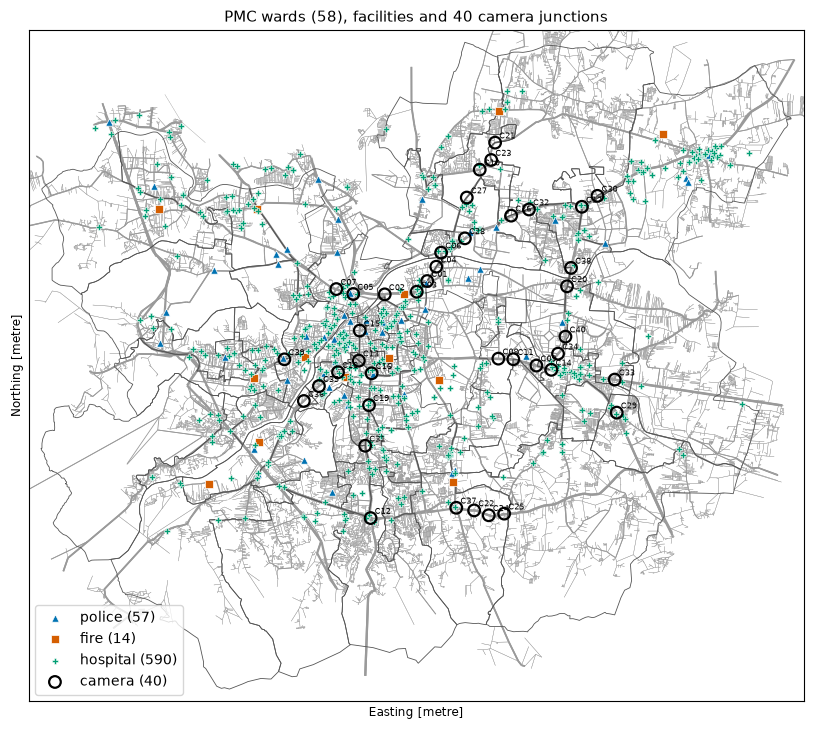

In [5]:
fig, ax = plt.subplots(figsize=(10, 10))
draw_roads(ax)
frame(ax, f"PMC wards ({len(wards)}), facilities and {len(cameras)} camera junctions")
for agency, marker, color in [("police", "^", OKABE_ITO["blue"]), ("fire", "s", OKABE_ITO["vermillion"])]:
    pts = [s for s in facilities.stations if s.agency.value == agency]
    xy = net.project([s.location.lat for s in pts], [s.location.lon for s in pts])
    ax.scatter(xy[:, 0], xy[:, 1], marker=marker, s=28, c=color, edgecolor="white",
               linewidth=0.5, zorder=4, label=f"{agency} ({len(pts)})")
hxy = net.project([h.location.lat for h in facilities.hospitals], [h.location.lon for h in facilities.hospitals])
ax.scatter(hxy[:, 0], hxy[:, 1], marker="P", s=22, c=OKABE_ITO["green"], edgecolor="white",
           linewidth=0.4, zorder=4, label=f"hospital ({len(facilities.hospitals)})")
cxy = net.project([c.lat for c in cameras], [c.lon for c in cameras])
ax.scatter(cxy[:, 0], cxy[:, 1], marker="o", s=70, facecolor="none", edgecolor=OKABE_ITO["black"],
           linewidth=1.6, zorder=5, label=f"camera ({len(cameras)})")
for c, (x, y) in zip(cameras, cxy, strict=True):
    ax.annotate(c.id, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=6, zorder=6)
ax.legend(loc="lower left", frameon=True)
fig.savefig(FIGURES / "02_network_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## Monsoon: flood effects at the worst hour of the week
The hour with the highest flood stage (ties: most accumulated rain) is found automatically.

worst hour: Thu 16 Jul 17:00
rain 9.6 mm/h, 3-h accumulation 31.2 mm, stage 1
flood-prone edges 1,781; impassable 300; slowed 740


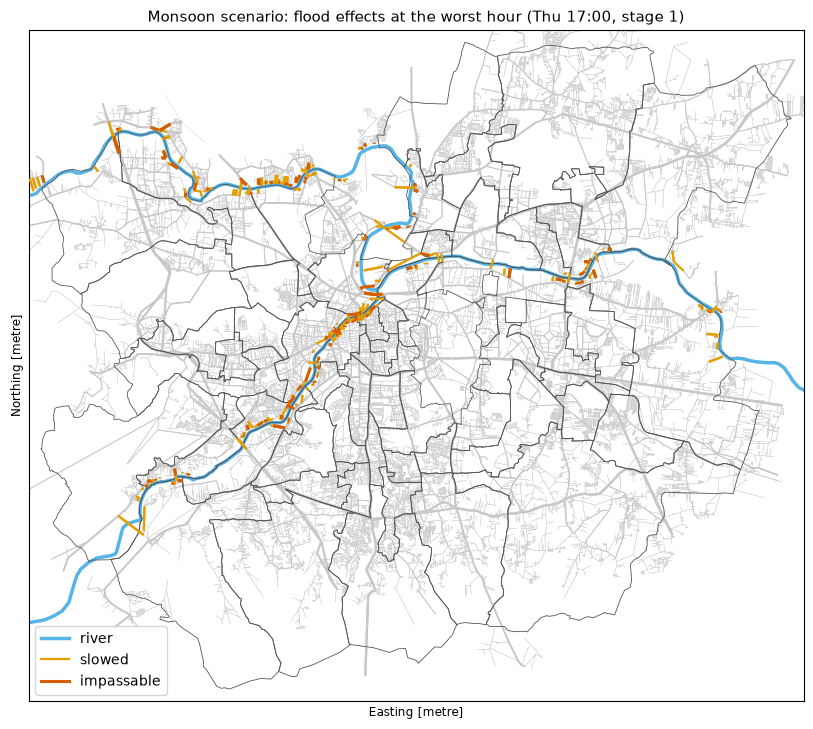

In [6]:
monsoon = load_scenario("monsoon")
ms = ScenarioState(monsoon, net, base.project.timezone)
hours = [monsoon.start + timedelta(hours=h) for h in range(monsoon.days * 24)]
t_peak = max(hours, key=lambda t: (ms.flood_stage(t), ms.rain_accum_mm(t, monsoon.flooding.window_h)))
print("worst hour:", t_peak.strftime("%a %d %b %H:%M"))
f = ms.edge_factors(t_peak)
print(f"rain {ms.rain_mm_h(t_peak):.1f} mm/h, 3-h accumulation {ms.rain_accum_mm(t_peak, 3):.1f} mm, "
      f"stage {ms.flood_stage(t_peak)}")
print(f"flood-prone edges {ms.flood_prone.sum():,}; impassable {int((f == 0).sum()):,}; "
      f"slowed {int(((f > 0) & (f < 1)).sum()):,}")
rivers = gpd.read_file(base.paths.resolve("data_raw") / geo.rivers.raw_file).to_crs(geo.network.projected_crs)
fig, ax = plt.subplots(figsize=(10, 10))
draw_roads(ax, color="#c8c8c8")
rivers.plot(ax=ax, color=OKABE_ITO["sky"], linewidth=2.5, zorder=2)
frame(ax, f"Monsoon scenario: flood effects at the worst hour ({t_peak:%a %H:%M}, stage {ms.flood_stage(t_peak)})")
ax.add_collection(LineCollection(segments((f > 0) & (f < 1)), linewidths=1.6, colors=OKABE_ITO["orange"], zorder=3))
ax.add_collection(LineCollection(segments(f == 0), linewidths=2.2, colors=OKABE_ITO["vermillion"], zorder=4))
ax.legend(handles=[Line2D([], [], color=OKABE_ITO["sky"], lw=2.5, label="river"),
                   Line2D([], [], color=OKABE_ITO["orange"], lw=1.6, label="slowed"),
                   Line2D([], [], color=OKABE_ITO["vermillion"], lw=2.2, label="impassable")],
          loc="lower left")
fig.savefig(FIGURES / "02_monsoon_flooding_synthetic.png", dpi=160, bbox_inches="tight")
plt.show()

## Ganeshotsav: immersion-day closures (day 7, 12:00)

effect 'closed': route edges 203, influence edges 5,600, nodes near routes 2,428
street matches: {'old_city_immersion_routes: Laxmi Road': 8, 'old_city_immersion_routes: Lokmanya Tilak Marg': 54, 'old_city_immersion_routes: R. B. Kumthekar Marg': 10, 'old_city_immersion_routes: Narsimha Chintaman Kelkar Marg': 29, 'old_city_immersion_routes: Shivaji Road': 68, 'old_city_immersion_routes: Bajirao Road': 34}


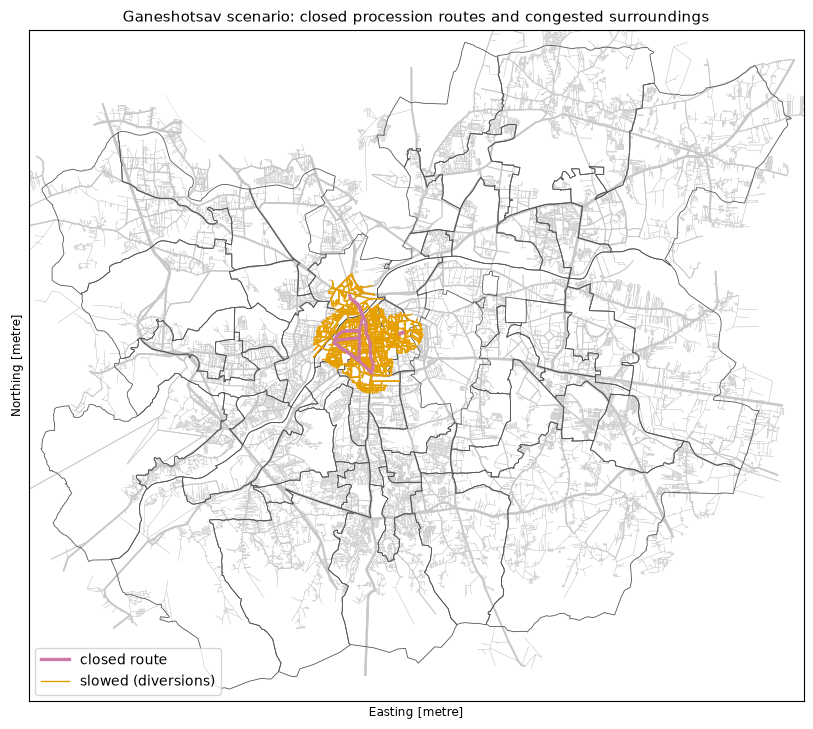

In [7]:
gan = load_scenario("ganeshotsav")
gs = ScenarioState(gan, net, base.project.timezone)
t_imm = gan.start + timedelta(days=6, hours=12)
g = gs.edge_factors(t_imm)
print(f"effect {gs.festival_effect(t_imm)!r}: route edges {gs.route_edges.sum():,}, "
      f"influence edges {gs.influence_edges.sum():,}, nodes near routes {gs.near_route_nodes.sum():,}")
print("street matches:", gs.route_match_counts)
fig, ax = plt.subplots(figsize=(10, 10))
draw_roads(ax, color="#c8c8c8")
frame(ax, "Ganeshotsav scenario: closed procession routes and congested surroundings")
ax.add_collection(LineCollection(segments(gs.influence_edges), linewidths=1.0, colors=OKABE_ITO["orange"], zorder=3))
ax.add_collection(LineCollection(segments(g == 0), linewidths=2.4, colors=OKABE_ITO["purple"], zorder=4))
ax.legend(handles=[Line2D([], [], color=OKABE_ITO["purple"], lw=2.4, label="closed route"),
                   Line2D([], [], color=OKABE_ITO["orange"], lw=1.0, label="slowed (diversions)")],
          loc="lower left")
fig.savefig(FIGURES / "02_ganeshotsav_closures_synthetic.png", dpi=160, bbox_inches="tight")
plt.show()

## Speed calibration against Google Maps (D-026)
Per-hour speed factors fitted to Google Maps typical travel times that the user collected for 10 routes at
10:00, 14:00 and 19:00 (`results/geo/maps_check_google_2026-10-20.csv`). Step 1 (pre-specified: fit on 4
routes, test on 6) over-corrected; step 2 (leave-one-route-out over all 10, added after step 1 and disclosed
in D-026) is the adopted, honest error estimate. "All routes" is in-sample. From
`results/geo/speed_calibration.json` (`python -m resqcity.geo.calibrate_speeds`).

In [8]:
import json

cal = json.loads((base.paths.resolve("results") / "geo" / "speed_calibration.json").read_text(encoding="utf-8"))
s1, s2 = cal["step1_prespecified_fit4_holdout6"], cal["step2_leave_one_route_out_all10"]
rows = {"step 1 hold-out: baseline (D-014)": s1["holdout_before"],
        "step 1 hold-out: fitted on 4 routes": s1["holdout_after"],
        "step 2 LORO: baseline (D-014)": s2["baseline"],
        "step 2 LORO: calibrated (adopted)": s2["calibrated"],
        "all 10 routes, in-sample": cal["final_all_routes"]}
cols = ["n", "median_abs_pct_error_vs_mid", "share_within_google_range"]
display(pd.DataFrame(rows).T[cols].round(3))
print("adopted slow-down factors by hour (Google / baseline model):",
      {h: round(f, 2) for h, f in cal["final_factors_by_hour"].items()})
pd.read_csv(base.paths.resolve("results") / "geo" / "speed_calibration_routes.csv").round(1)

,n,median_abs_pct_error_vs_mid,share_within_google_range
step 1 hold-out: baseline (D-014),18.0,11.535,0.722
step 1 hold-out: fitted on 4 routes,18.0,19.863,0.778
step 2 LORO: baseline (D-014),30.0,19.333,0.733
step 2 LORO: calibrated (adopted),30.0,17.163,0.800
"all 10 routes, in-sample",30.0,15.500,0.967


adopted slow-down factors by hour (Google / baseline model): {'10': 1.06, '14': 1.49, '19': 1.14}


,from,to,holdout,hour,g_low,g_high,g_mid,model_baseline,model_fit4,model_calibrated
0,Shivajinagar bus stand,Swargate bus stand,False,10,12.0,24.0,18.0,15.0,16.2,15.9
1,Shivajinagar bus stand,Swargate bus stand,False,14,16.0,30.0,23.0,10.8,17.5,16.1
2,Shivajinagar bus stand,Swargate bus stand,False,19,18.0,35.0,26.5,16.2,20.4,18.5
3,Pune railway station,Deccan Gymkhana,False,10,10.0,20.0,15.0,18.3,19.8,19.5
4,Pune railway station,Deccan Gymkhana,False,14,12.0,22.0,17.0,12.5,20.1,18.6
5,Pune railway station,Deccan Gymkhana,False,19,16.0,30.0,23.0,20.0,25.2,22.9
6,Kothrud depot,Viman Nagar (Phoenix mall),False,10,40.0,75.0,57.5,55.6,60.3,59.2
7,Kothrud depot,Viman Nagar (Phoenix mall),False,14,35.0,65.0,50.0,38.1,61.5,56.7
8,Kothrud depot,Viman Nagar (Phoenix mall),False,19,40.0,80.0,60.0,60.8,76.5,69.4
9,Katraj chowk,Shivajinagar bus stand,False,10,28.0,55.0,41.5,30.5,33.1,32.4


## Travel-time sanity check
From `results/geo/sanity_travel_times.csv` (`python -m resqcity.geo.sanity`), with the calibrated speeds. These are model outputs to compare with local experience, not observations.

In [9]:
pd.read_csv(base.paths.resolve("results") / "geo" / "sanity_travel_times.csv").query("profile == 'default'")

,from,to,holdout,profile,depart_local,route_km,minutes,avg_kph,snap_from_m,snap_to_m
0,Shivajinagar bus stand,Swargate bus stand,False,default,Tue 03:00,4.28,7.5,34.0,10,3
1,Shivajinagar bus stand,Swargate bus stand,False,default,Tue 10:00,4.28,15.9,16.1,10,3
2,Shivajinagar bus stand,Swargate bus stand,False,default,Tue 14:00,4.28,16.1,15.9,10,3
3,Shivajinagar bus stand,Swargate bus stand,False,default,Tue 19:00,4.28,18.5,13.9,10,3
8,Pune railway station,Deccan Gymkhana,False,default,Tue 03:00,4.70,8.5,33.3,102,50
9,Pune railway station,Deccan Gymkhana,False,default,Tue 10:00,4.70,19.5,14.5,102,50
10,Pune railway station,Deccan Gymkhana,False,default,Tue 14:00,4.70,18.6,15.2,102,50
11,Pune railway station,Deccan Gymkhana,False,default,Tue 19:00,4.70,22.9,12.3,102,50
16,Kothrud depot,Viman Nagar (Phoenix mall),False,default,Tue 03:00,15.83,25.4,37.3,3,148
17,Kothrud depot,Viman Nagar (Phoenix mall),False,default,Tue 10:00,15.27,59.2,15.5,3,148


## Synthetic incidents per scenario (replication 0)

In [10]:
inc_cfg, req = load_incidents_config(), load_requirements_config()
rows = []
for name in ["normal", "monsoon", "ganeshotsav"]:
    sc = load_scenario(name)
    gen = IncidentGenerator(net, ScenarioState(sc, net, base.project.timezone), inc_cfg, req)
    df = to_frame(gen.generate(base.random.seed_base, 0))
    agencies = (df[["req_ambulance", "req_police", "req_fire"]] > 0).sum(axis=1)
    rows.append({"scenario": name, "incidents": len(df),
                 "expected": round(gen.ward_hour_rates()["expected"].sum(), 1),
                 **df["type"].value_counts().to_dict(),
                 "needs_fire": int((df["req_fire"] > 0).sum()),
                 "multi_agency": int((agencies >= 2).sum())})
pd.DataFrame(rows).fillna(0).set_index("scenario")

,incidents,expected,fire_smoke,accident,other,needs_fire,multi_agency,crowd
scenario,,,,,,,,
normal,34,39.1,21,12,1,22,25,0.0
monsoon,37,41.5,24,12,1,25,28,0.0
ganeshotsav,41,46.4,22,17,1,23,29,1.0


## Load time of the canonical OSMnx graph (acceptance: < 10 s)

In [11]:
import osmnx as ox

t0 = time.perf_counter()
G = ox.load_graphml(processed / geo.network.graphml_file)
print(f"OSMnx graphml loaded in {time.perf_counter() - t0:.1f} s ({G.number_of_nodes():,} nodes)")

OSMnx graphml loaded in 6.1 s (48,821 nodes)
